# 03. GNN Comparison: GCN, GAT, GraphSAGE

All three models use BERT features of every node and the propagation graph. The architecture follows the official UPFD / PyG example:

`conv → ReLU → graph pooling → concatenate with projected root (news) vector → Linear → ReLU → Linear`

| Setting | Value here | Official UPFD example |
|---|---|---|
| Conv layers | `NUM_LAYERS = 1` | 1 |
| Pooling | `READOUT = "max"` | max |
| Root fusion | `ROOT_FUSION = True` | yes |
| Edges | as stored (parent to child) | made undirected |
| Training | same for all models, early stopping on validation macro-F1 | fixed epochs |

Only the convolution differs between models. Change the settings in section 2 to run other variants (for example `READOUT = "mean"`, `NUM_LAYERS = 2`, `ROOT_FUSION = False`). Results are saved per setting.

Reference: Dou et al., User Preference-aware Fake News Detection (SIGIR 2021), https://github.com/safe-graph/GNN-FakeNews

## 1. Imports

In [1]:
# Imports.
import sys, json, time, platform, warnings, random, logging, gc
from pathlib import Path
import psutil

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, precision_recall_fscore_support)
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, GATConv, SAGEConv, global_mean_pool, global_max_pool
from torch_geometric.utils import to_undirected

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)


def rss_mb():
    return psutil.Process().memory_info().rss / 1e6


In [2]:
# Software versions and the device used for this run.
versions = {"Python": sys.version.split()[0], "Platform": platform.platform(), "NumPy": np.__version__,
            "Pandas": pd.__version__, "SciPy": scipy.__version__, "scikit-learn": sklearn.__version__,
            "PyTorch": torch.__version__, "PyG": torch_geometric.__version__}
for k, v in versions.items():
    print(f"{k:<14}{v}")

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("Device: CUDA ->", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("Device: CPU")


Python        3.13.13
Platform      Windows-11-10.0.26200-SP0
NumPy         2.4.3
Pandas        2.3.3
SciPy         1.17.1
scikit-learn  1.8.0
PyTorch       2.11.0+cpu
PyG           2.8.1
Device: CPU


## 2. Configuration

In [3]:
# Shared settings, paths, data loader and graph statistics (see upfd_common.py).
from upfd_common import *


Working directory: C:\Users\shara\FakeNews-detection-GNN\fake_news_gnn_final_notebooks
Project root     : C:\Users\shara\FakeNews-detection-GNN
UPFD data root   : C:\Users\shara\FakeNews-detection-GNN\data\upfd (found)


In [4]:
# Experiment settings. These are the same for all three models.
SEEDS = [42, 43, 44, 45, 46]
GNN_MODELS = ["GCN", "GAT", "GraphSAGE"]

EDGE_MODE = "as_stored"
READOUT = "max"
NUM_LAYERS = 1
ROOT_FUSION = True
NUM_WORKERS = 0

CFG = {
    "hidden_dim": 128,
    "dropout": 0.5,
    "lr": 1e-3,
    "weight_decay": 5e-4,
    "max_epochs": 100,
    "patience": 15,
    "gat_heads": 1,
    "gat_attn_dropout": 0.0,
}
BATCH_SIZE = {"politifact": 32, "gossipcop": 64}
EVAL_BATCH_SIZE = {"politifact": 64, "gossipcop": 128}

assert EDGE_MODE in ("as_stored", "undirected")
assert READOUT in ("mean", "max")
assert NUM_LAYERS >= 1
assert CFG["hidden_dim"] % CFG["gat_heads"] == 0

SETTING = f"L{NUM_LAYERS}_{READOUT}_{'root' if ROOT_FUSION else 'noroot'}_{EDGE_MODE}"

GNN_METRICS_DIR = METRICS_DIR / "gnn"
GNN_PRED_DIR = GNN_METRICS_DIR / "predictions"
GNN_FIG_DIR = FIGURES_DIR / "gnn"
GNN_LOG_DIR = LOGS_DIR / "gnn"
GNN_CKPT_DIR = CHECKPOINTS_DIR / "gnn"
for _d in (GNN_METRICS_DIR, GNN_PRED_DIR, GNN_FIG_DIR, GNN_LOG_DIR, GNN_CKPT_DIR):
    _d.mkdir(parents=True, exist_ok=True)


# File name prefix for one run.
def run_tag(model_name, dataset_key, seed):
    return f"{model_name.lower()}_{dataset_key}_seed{seed}_{SETTING}"


RUN_ID = time.strftime("%Y%m%d_%H%M%S")
LOG_PATH = GNN_LOG_DIR / f"gnn_comparison_{RUN_ID}.log"
logger = logging.getLogger("gnn_comparison")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_fh = logging.FileHandler(LOG_PATH, mode="a", encoding="utf-8")
_fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(_fh)
logger.info("Notebook 03 started | setting=%s | seeds=%s | cfg=%s | device=%s", SETTING, SEEDS, CFG, DEVICE)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


print("Setting:", SETTING)
print("Seeds  :", SEEDS)

Setting: L1_max_root_as_stored
Seeds  : [42, 43, 44, 45, 46]


## 3. Load data and build graphs

In [5]:
# Load both datasets.
RAW, LOAD_TIME = {}, {}
for name in DATASETS:
    t0 = time.perf_counter()
    RAW[name] = load_upfd_raw(name)
    LOAD_TIME[name] = time.perf_counter() - t0
    r = RAW[name]
    print(f"{DATASET_TITLES[name]:<11} loaded in {LOAD_TIME[name]:5.1f}s | graphs={r['n_graphs']:,} | nodes={r['n_nodes']:,} | "
          f"edges={len(r['edges']):,} | features {r['X'].shape}")
    assert len(r["classes_raw"]) == 2
    assert r["X"].shape[1] == EXPECTED_FEATURE_DIM
print(f"CPU memory after loading: {rss_mb():.0f} MB")

PolitiFact  loaded in   4.1s | graphs=314 | nodes=41,054 | edges=40,740 | features (41054, 768)
GossipCop   loaded in  19.3s | graphs=5,464 | nodes=314,262 | edges=308,798 | features (314262, 768)
CPU memory after loading: 2685 MB


In [6]:
# Convert one graph to a PyG Data object.
def graph_to_data(raw, i, edge_mode=EDGE_MODE):
    a, b = int(raw["node_slice"][i]), int(raw["node_slice"][i + 1])
    x = torch.from_numpy(raw["X"][a:b].toarray())
    edge_index = torch.from_numpy(np.ascontiguousarray(local_edges(raw, i).T))
    if edge_mode == "undirected":
        edge_index = to_undirected(edge_index, num_nodes=x.shape[0])
    return Data(x=x, edge_index=edge_index, y=torch.tensor([int(raw["y"][i])], dtype=torch.long),
                graph_idx=torch.tensor([int(i)], dtype=torch.long))


GRAPHS, BUILD_TIME = {}, {}
for name in DATASETS:
    raw = RAW[name]
    t0 = time.perf_counter()
    GRAPHS[name] = {s: [graph_to_data(raw, int(i)) for i in tqdm(raw["splits"][s], desc=f"{name}/{s}", leave=False)] for s in SPLITS}
    BUILD_TIME[name] = time.perf_counter() - t0
    print(f"{DATASET_TITLES[name]:<11}: " + " | ".join(f"{s}={len(GRAPHS[name][s])}" for s in SPLITS) + f" graphs built in {BUILD_TIME[name]:.1f}s")
print(f"CPU memory after building graphs: {rss_mb():.0f} MB")

politifact/train:   0%|          | 0/62 [00:00<?, ?it/s]

politifact/val:   0%|          | 0/31 [00:00<?, ?it/s]

politifact/test:   0%|          | 0/221 [00:00<?, ?it/s]

PolitiFact : train=62 | val=31 | test=221 graphs built in 0.8s


gossipcop/train:   0%|          | 0/1092 [00:00<?, ?it/s]

gossipcop/val:   0%|          | 0/546 [00:00<?, ?it/s]

gossipcop/test:   0%|          | 0/3826 [00:00<?, ?it/s]

GossipCop  : train=1092 | val=546 | test=3826 graphs built in 4.7s
CPU memory after building graphs: 3805 MB


## 4. Data checks

In [7]:
# Check that the official splits are valid and that the graph objects follow them.
for name in DATASETS:
    raw = RAW[name]
    split_df, overlaps, coverage = check_splits(raw)
    assert all(v == 0 for v in overlaps.values()), f"{name}: splits overlap -> data leakage"
    assert split_df["duplicates"].sum() == 0 and split_df["out_of_range"].sum() == 0
    ids = {s: {int(g.graph_idx) for g in GRAPHS[name][s]} for s in SPLITS}
    assert not (ids["train"] & ids["val"]) and not (ids["train"] & ids["test"]) and not (ids["val"] & ids["test"])
print("Split checks passed (official indices, disjoint, in range).")


Split checks passed (official indices, disjoint, in range).


In [8]:
# Check that the graph objects match the raw files.
rng = np.random.default_rng(SEED)
for name in DATASETS:
    raw = RAW[name]
    for s in SPLITS:
        lst, idx = GRAPHS[name][s], raw["splits"][s]
        assert [int(g.graph_idx) for g in lst] == idx.tolist(), "graph order differs from the official split order"
        assert all(int(g.y) == int(raw["y"][int(g.graph_idx)]) for g in lst), "label mismatch"
        assert all(g.x.shape[1] == EXPECTED_FEATURE_DIM and g.x.dtype == torch.float32 for g in lst)
        assert all(g.x.shape[0] == graph_num_nodes(raw, int(g.graph_idx)) for g in lst), "node count mismatch"
        roots = torch.stack([g.x[0] for g in lst]).numpy()
        assert np.array_equal(roots, root_features(raw, idx)), "feature row of local node 0 differs from raw file"
        for k in rng.choice(len(lst), size=min(100, len(lst)), replace=False):
            g, gi = lst[int(k)], int(lst[int(k)].graph_idx)
            assert np.array_equal(g.x.numpy(), raw["X"][raw["node_slice"][gi]:raw["node_slice"][gi + 1]].toarray())
            if EDGE_MODE == "as_stored":
                assert np.array_equal(g.edge_index.t().numpy(), local_edges(raw, gi)), "edges differ from A.txt (after coalesce)"
            ei = g.edge_index
            assert ei.numel() == 0 or (int(ei.min()) >= 0 and int(ei.max()) < g.x.shape[0]), "edge points outside its own graph"
    print(f"{DATASET_TITLES[name]:<11}: Data objects match the raw files (order, labels, features, edges).")

PolitiFact : Data objects match the raw files (order, labels, features, edges).
GossipCop  : Data objects match the raw files (order, labels, features, edges).


In [9]:
# Confirm that node 0 is the news root and find the direction of the edges.
ROOT_CHECK = {name: root_convention_check(RAW[name]) for name in DATASETS}
for name in DATASETS:
    summarize_root_check(ROOT_CHECK[name], DATASET_TITLES[name])

EDGE_DIRECTION = {}
for name in DATASETS:
    rc = ROOT_CHECK[name]
    EDGE_DIRECTION[name] = "parent_to_child" if rc["node0_unique_source"].mean() >= rc["node0_unique_sink"].mean() else "child_to_parent"
print("Inferred edge direction:", EDGE_DIRECTION)


Inferred edge direction: {'politifact': 'parent_to_child', 'gossipcop': 'parent_to_child'}


In [10]:
# Check that mini-batching keeps the graphs separate.
def check_batching(graphs):
    loader = DataLoader(graphs, batch_size=len(graphs), shuffle=False, num_workers=0)
    batch = next(iter(loader))
    src, dst = batch.edge_index
    assert bool((batch.batch[src] == batch.batch[dst]).all()), "an edge connects two different graphs!"
    assert batch.num_graphs == len(graphs) and batch.ptr.numel() == len(graphs) + 1
    assert batch.y.shape == (len(graphs),) and batch.graph_idx.shape == (len(graphs),)
    assert batch.x.shape == (sum(g.x.shape[0] for g in graphs), EXPECTED_FEATURE_DIM)
    for k, g in enumerate(graphs):
        lo, hi = int(batch.ptr[k]), int(batch.ptr[k + 1])
        assert torch.equal(batch.x[lo:hi], g.x), "node features were mixed up"
        mask = batch.batch[src] == k
        assert torch.equal(batch.edge_index[:, mask] - lo, g.edge_index), "edges were mixed up"
        assert int(batch.y[k]) == int(g.y)
    return batch


for name in DATASETS:
    b = check_batching(GRAPHS[name]["train"][:8])
    print(f"{DATASET_TITLES[name]:<11}: batch of {b.num_graphs} graphs -> x {tuple(b.x.shape)}, edge_index {tuple(b.edge_index.shape)}, "
          f"y {tuple(b.y.shape)}, batch vector {tuple(b.batch.shape)}; graphs stay separate.")

PolitiFact : batch of 8 graphs -> x (1491, 768), edge_index (2, 1483), y (8,), batch vector (1491,); graphs stay separate.
GossipCop  : batch of 8 graphs -> x (539, 768), edge_index (2, 531), y (8,), batch vector (539,); graphs stay separate.


In [11]:
# Free the raw feature matrices and record data preparation costs.
for name in DATASETS:
    RAW[name]["X"] = None
gc.collect()
print(f"CPU memory after releasing raw features: {rss_mb():.0f} MB")

COST = pd.DataFrame([{"dataset": DATASET_TITLES[n], "load_time_s": round(LOAD_TIME[n], 2), "graph_build_time_s": round(BUILD_TIME[n], 2),
                      "nodes": RAW[n]["n_nodes"], "graphs": RAW[n]["n_graphs"]} for n in DATASETS])
save_dataframe(COST, GNN_METRICS_DIR / "data_cost.csv")
display(COST)

CPU memory after releasing raw features: 1648 MB


,dataset,load_time_s,graph_build_time_s,nodes,graphs
0,PolitiFact,4.09,0.80,41054,314
1,GossipCop,19.28,4.67,314262,5464


## 5. Model and training code

In [12]:
# Accuracy, macro metrics, ROC-AUC and per-class metrics.
def compute_metrics(y_true, y_pred, y_score):
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    out = {
        "n": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan,
    }
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    for c in (0, 1):
        out[f"precision_class{c}"], out[f"recall_class{c}"], out[f"f1_class{c}"], out[f"support_class{c}"] = p[c], r[c], f[c], int(s[c])
    if FAKE_CLASS_INDEX is not None:
        real = 1 - FAKE_CLASS_INDEX
        out["precision_fake"], out["recall_fake"] = p[FAKE_CLASS_INDEX], r[FAKE_CLASS_INDEX]
        out["precision_real"], out["recall_real"] = p[real], r[real]
    return out


MODEL_COLORS = {"GCN": "#0072B2", "GAT": "#D55E00", "GraphSAGE": "#009E73"}


# Draw a confusion matrix on an existing axis.
def plot_confusion_ax(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    names = [CLASS_NAMES[0], CLASS_NAMES[1]]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(title); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    return cm


def append_run_metrics(rows, csv_path):
    """Append metric rows without relying on pandas merge-key dtypes.

    Older result CSVs may contain blank or numeric values in `setting`
    (for example, an all-NaN column is read as float64), while the current
    notebook writes a string setting. Comparing normalized key tuples avoids
    the float64/object merge error and preserves older rows.
    """
    new = pd.DataFrame(rows)
    key = ["dataset", "model", "seed", "split", "setting"]

    def normalise_key_value(column, value):
        if pd.isna(value):
            return "<MISSING>"
        if column == "seed":
            # CSV files may infer seed as 42.0 when older rows contain blanks.
            try:
                return str(int(float(value)))
            except (TypeError, ValueError, OverflowError):
                pass
        return str(value).strip()

    def row_key(row):
        return tuple(normalise_key_value(col, row[col]) for col in key)

    if csv_path.is_file():
        old = pd.read_csv(csv_path)
        for column in key:
            if column not in old.columns:
                old[column] = pd.NA

        existing_keys = {row_key(row) for _, row in old.iterrows()}
        keep_indices = []
        for idx, row in new.iterrows():
            current_key = row_key(row)
            if current_key not in existing_keys:
                keep_indices.append(idx)
                existing_keys.add(current_key)

        new_to_append = new.loc[keep_indices]
        combined = pd.concat([old, new_to_append], ignore_index=True, sort=False)
    else:
        combined = new.drop_duplicates(subset=key, keep="last")

    save_dataframe(combined, csv_path)
    return combined


# Save the history, predictions, metrics and metadata of one run.
def save_run_outputs(model_name, ds, seed, history, pred_df, metric_rows, meta):
    tag = run_tag(model_name, ds, seed)
    save_dataframe(history, GNN_LOG_DIR / f"{tag}_history.csv")
    save_dataframe(pred_df, GNN_PRED_DIR / f"{tag}_predictions.csv")
    append_run_metrics(metric_rows, GNN_METRICS_DIR / "gnn_metrics.csv")
    save_json(meta, GNN_METRICS_DIR / f"{tag}_metadata.json")
    return tag

In [13]:
# GNN model, data loaders and the training loop.
READOUTS = {"mean": global_mean_pool, "max": global_max_pool}


# Convolution, graph pooling, fusion with the news vector, then the classifier.
# Only the convolution differs between GCN, GAT and GraphSAGE.
class GraphClassifier(nn.Module):
    def __init__(self, convs, in_dim, hidden_dim, dropout, readout, root_fusion, stats_dim=0, n_classes=2):
        super().__init__()
        self.convs = nn.ModuleList(convs)
        self.dropout = dropout
        self.readout = READOUTS[readout]
        self.root_fusion = root_fusion
        self.stats_dim = stats_dim
        fused_dim = hidden_dim
        if root_fusion:
            self.root_lin = nn.Linear(in_dim, hidden_dim)
            fused_dim += hidden_dim
        if stats_dim:
            self.stats_lin = nn.Linear(stats_dim, hidden_dim)
            fused_dim += hidden_dim
        self.fuse = nn.Linear(fused_dim, hidden_dim) if fused_dim != hidden_dim else None
        self.out = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, edge_index, batch, ptr, stats=None):
        h = x
        for k, conv in enumerate(self.convs):
            h = F.relu(conv(h, edge_index))
            if k < len(self.convs) - 1:
                h = F.dropout(h, p=self.dropout, training=self.training)
        g = self.readout(h, batch)
        if self.fuse is not None:
            parts = [g]
            if self.root_fusion:
                parts.append(F.relu(self.root_lin(x[ptr[:-1]])))
            if self.stats_dim:
                parts.append(F.relu(self.stats_lin(stats)))
            g = F.relu(self.fuse(torch.cat(parts, dim=1)))
        g = F.dropout(g, p=self.dropout, training=self.training)
        return self.out(g)


# Create the convolution layers for the chosen architecture.
def make_convs(kind, in_dim):
    hidden, heads = CFG["hidden_dim"], CFG["gat_heads"]
    dims = [in_dim] + [hidden] * NUM_LAYERS
    convs = []
    for a, b in zip(dims[:-1], dims[1:]):
        if kind == "GCN":
            convs.append(GCNConv(a, b))
        elif kind == "GAT":
            convs.append(GATConv(a, b // heads, heads=heads, concat=True, dropout=CFG["gat_attn_dropout"]))
        else:
            convs.append(SAGEConv(a, b, aggr="mean"))
    return convs


def build_model(kind, in_dim, stats_dim=0):
    return GraphClassifier(make_convs(kind, in_dim), in_dim, CFG["hidden_dim"], CFG["dropout"], READOUT, ROOT_FUSION, stats_dim)


MODEL_BUILDERS = {m: (lambda in_dim, m=m: build_model(m, in_dim)) for m in GNN_MODELS}


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Shuffled loader for training and fixed-order loaders for evaluation.
def make_loaders(ds, seed):
    gen = torch.Generator()
    gen.manual_seed(seed)
    common = {"num_workers": NUM_WORKERS}
    return {
        "train": DataLoader(GRAPHS[ds]["train"], batch_size=BATCH_SIZE[ds], shuffle=True, generator=gen, **common),
        "train_eval": DataLoader(GRAPHS[ds]["train"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, **common),
        "val": DataLoader(GRAPHS[ds]["val"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, **common),
        "test": DataLoader(GRAPHS[ds]["test"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, **common),
    }


# Loss, predictions and scores for one data split.
def evaluate(model, loader):
    model.eval()
    total, n = 0.0, 0
    ys, preds, scores, gids = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            logits = model(batch.x, batch.edge_index, batch.batch, batch.ptr)
            total += F.cross_entropy(logits, batch.y, reduction="sum").item()
            n += batch.num_graphs
            proba = torch.softmax(logits, dim=1)
            ys.append(batch.y.cpu().numpy()); preds.append(logits.argmax(dim=1).cpu().numpy())
            scores.append(proba[:, 1].cpu().numpy()); gids.append(batch.graph_idx.cpu().numpy())
    return {"loss": total / n, "y_true": np.concatenate(ys), "y_pred": np.concatenate(preds),
            "y_score": np.concatenate(scores), "graph_idx": np.concatenate(gids)}


# Train one model on one dataset and seed. Early stopping uses validation macro-F1,
# ties are broken by validation loss, and the best epoch is restored before testing.
def run_experiment(model_name, ds, seed):
    set_seed(seed)
    loaders = make_loaders(ds, seed)
    in_dim = GRAPHS[ds]["train"][0].x.shape[1]
    model = MODEL_BUILDERS[model_name](in_dim).to(DEVICE)
    n_params = count_parameters(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    best = {"f1": -1.0, "loss": np.inf, "epoch": 0, "state": None}
    bad_epochs, history = 0, []
    t_start = time.perf_counter()
    try:
        for epoch in range(1, CFG["max_epochs"] + 1):
            t_ep = time.perf_counter()
            model.train()
            running, seen = 0.0, 0
            for batch in loaders["train"]:
                batch = batch.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                logits = model(batch.x, batch.edge_index, batch.batch, batch.ptr)
                loss = F.cross_entropy(logits, batch.y)
                loss.backward()
                optimizer.step()
                running += loss.item() * batch.num_graphs
                seen += batch.num_graphs
            tr, va = evaluate(model, loaders["train_eval"]), evaluate(model, loaders["val"])
            tr_m = compute_metrics(tr["y_true"], tr["y_pred"], tr["y_score"])
            va_m = compute_metrics(va["y_true"], va["y_pred"], va["y_score"])
            history.append({"epoch": epoch, "train_loss_running": running / seen, "train_loss": tr["loss"], "train_acc": tr_m["accuracy"],
                            "val_loss": va["loss"], "val_acc": va_m["accuracy"], "val_f1_macro": va_m["f1_macro"],
                            "val_roc_auc": va_m["roc_auc"], "epoch_seconds": time.perf_counter() - t_ep})
            better = (va_m["f1_macro"] > best["f1"] + 1e-12) or (abs(va_m["f1_macro"] - best["f1"]) <= 1e-12 and va["loss"] < best["loss"])
            if better:
                best.update(f1=va_m["f1_macro"], loss=va["loss"], epoch=epoch, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
                bad_epochs = 0
            else:
                bad_epochs += 1
                if bad_epochs >= CFG["patience"]:
                    break
    except RuntimeError as exc:
        if "out of memory" in str(exc).lower():
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
            raise RuntimeError(f"CUDA out of memory for {model_name} on {ds}. Lower BATCH_SIZE and EVAL_BATCH_SIZE and restart the kernel.") from exc
        raise
    train_time = time.perf_counter() - t_start

    model.load_state_dict(best["state"])
    va = evaluate(model, loaders["val"])
    te = evaluate(model, loaders["test"])
    history = pd.DataFrame(history)
    best_row = history[history["epoch"] == best["epoch"]].iloc[0]

    rows = []
    for split, res in (("val", va), ("test", te)):
        rows.append({"dataset": DATASET_TITLES[ds], "dataset_key": ds, "model": model_name, "seed": seed, "split": split,
                     "setting": SETTING, "edge_mode": EDGE_MODE, "readout": READOUT, "layers": NUM_LAYERS, "root_fusion": ROOT_FUSION,
                     **compute_metrics(res["y_true"], res["y_pred"], res["y_score"])})
    pred_df = pd.concat([pd.DataFrame({"split": s, "graph_idx": r["graph_idx"], "y_true": r["y_true"], "y_pred": r["y_pred"], "p_class1": r["y_score"]})
                         for s, r in (("val", va), ("test", te))], ignore_index=True)
    tag = run_tag(model_name, ds, seed)
    ckpt = GNN_CKPT_DIR / f"{tag}.pt"
    torch.save({"state_dict": best["state"], "model": model_name, "in_dim": in_dim, "cfg": CFG, "setting": SETTING,
                "seed": seed, "dataset": ds, "best_epoch": best["epoch"]}, ckpt)

    meta = {"dataset": DATASET_TITLES[ds], "dataset_key": ds, "model": model_name, "seed": seed, "setting": SETTING,
            "edge_mode": EDGE_MODE, "readout": READOUT, "layers": NUM_LAYERS, "root_fusion": ROOT_FUSION, "cfg": CFG,
            "batch_size": BATCH_SIZE[ds], "n_params": n_params, "device": str(DEVICE),
            "best_epoch": best["epoch"], "epochs_run": int(len(history)), "train_time_s": round(train_time, 2),
            "peak_gpu_mb": round(torch.cuda.max_memory_allocated() / 1e6, 1) if DEVICE.type == "cuda" else None,
            "cpu_rss_mb": round(rss_mb(), 1),
            "train_loss_at_best": float(best_row["train_loss"]), "val_loss_at_best": float(best_row["val_loss"]),
            "train_acc_at_best": float(best_row["train_acc"]), "val_acc_at_best": float(best_row["val_acc"]),
            "val_f1_at_best": float(best_row["val_f1_macro"]), "run_id": RUN_ID}
    save_run_outputs(model_name, ds, seed, history, pred_df, rows, meta)
    t = rows[1]
    print(f"{model_name:<10} {DATASET_TITLES[ds]:<11} seed {seed} | best epoch {best['epoch']:>3}/{len(history)} | "
          f"test acc {t['accuracy']:.3f} macro-F1 {t['f1_macro']:.3f} | {train_time:.0f}s")
    logger.info("%s | %s | seed=%d | best_epoch=%d | time=%.1fs | test_f1=%.4f", model_name, ds, seed, best["epoch"], train_time, t["f1_macro"])
    return rows


show_cols = ["dataset", "model", "seed", "split", "n", "accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc"]
GNN_ROWS = []


# Run one architecture on both datasets for all seeds.
def run_model(model_name):
    for seed in SEEDS:
        for ds in DATASETS:
            GNN_ROWS.extend(run_experiment(model_name, ds, seed))
    t = pd.DataFrame([r for r in GNN_ROWS if r["model"] == model_name and r["split"] == "test"])
    display(t.groupby("dataset")[["accuracy", "f1_macro", "roc_auc"]].agg(["mean", "std"]).round(4))

In [14]:
# Check that each model builds and returns the correct output shape.
for m in GNN_MODELS:
    mdl = MODEL_BUILDERS[m](EXPECTED_FEATURE_DIM).to(DEVICE).eval()
    batch = next(iter(DataLoader(GRAPHS["politifact"]["train"][:4], batch_size=4))).to(DEVICE)
    with torch.no_grad():
        logits = mdl(batch.x, batch.edge_index, batch.batch, batch.ptr)
    assert logits.shape == (batch.num_graphs, 2)
    print(f"{m:<10} {type(mdl.convs[0]).__name__:<9} layers={len(mdl.convs)} parameters={count_parameters(mdl):,}")
print(MODEL_BUILDERS["GraphSAGE"](EXPECTED_FEATURE_DIM))

GCN        GCNConv   layers=1 parameters=230,018
GAT        GATConv   layers=1 parameters=230,274
GraphSAGE  SAGEConv  layers=1 parameters=328,322
GraphClassifier(
  (convs): ModuleList(
    (0): SAGEConv(768, 128, aggr=mean)
  )
  (root_lin): Linear(in_features=768, out_features=128, bias=True)
  (fuse): Linear(in_features=256, out_features=128, bias=True)
  (out): Linear(in_features=128, out_features=2, bias=True)
)


## 6. Training

GCN adds self-loops itself, GAT adds self-loops and learns attention weights, GraphSAGE keeps the node's own vector separate from the mean of its neighbours. Each run trains with early stopping on validation macro-F1, restores the best epoch and evaluates the test split once. Training histories and predictions are saved for every run and compared in the next section.

### 6.1 GCN

In [15]:
run_model("GCN")

GCN        PolitiFact  seed 42 | best epoch  21/36 | test acc 0.814 macro-F1 0.814 | 9s
GCN        GossipCop   seed 42 | best epoch  19/34 | test acc 0.954 macro-F1 0.954 | 117s
GCN        PolitiFact  seed 43 | best epoch  24/39 | test acc 0.824 macro-F1 0.823 | 15s
GCN        GossipCop   seed 43 | best epoch  22/37 | test acc 0.950 macro-F1 0.950 | 122s
GCN        PolitiFact  seed 44 | best epoch  22/37 | test acc 0.824 macro-F1 0.823 | 13s
GCN        GossipCop   seed 44 | best epoch  35/50 | test acc 0.956 macro-F1 0.956 | 171s
GCN        PolitiFact  seed 45 | best epoch  31/46 | test acc 0.833 macro-F1 0.832 | 17s
GCN        GossipCop   seed 45 | best epoch   6/21 | test acc 0.941 macro-F1 0.941 | 70s
GCN        PolitiFact  seed 46 | best epoch  31/46 | test acc 0.828 macro-F1 0.828 | 17s
GCN        GossipCop   seed 46 | best epoch   9/24 | test acc 0.944 macro-F1 0.944 | 83s


accuracy         f1_macro         roc_auc        
               mean     std     mean     std    mean     std
dataset                                                     
GossipCop    0.9491  0.0063   0.9491  0.0063  0.9854  0.0038
PolitiFact   0.8244  0.0067   0.8242  0.0067  0.8882  0.0048

### 6.2 GAT

In [16]:
run_model("GAT")

GAT        PolitiFact  seed 42 | best epoch  26/41 | test acc 0.828 macro-F1 0.828 | 17s
GAT        GossipCop   seed 42 | best epoch  11/26 | test acc 0.954 macro-F1 0.954 | 98s
GAT        PolitiFact  seed 43 | best epoch  20/35 | test acc 0.814 macro-F1 0.814 | 14s
GAT        GossipCop   seed 43 | best epoch  19/34 | test acc 0.967 macro-F1 0.967 | 126s
GAT        PolitiFact  seed 44 | best epoch  21/36 | test acc 0.814 macro-F1 0.814 | 15s
GAT        GossipCop   seed 44 | best epoch  21/36 | test acc 0.966 macro-F1 0.966 | 102s
GAT        PolitiFact  seed 45 | best epoch  27/42 | test acc 0.833 macro-F1 0.832 | 11s
GAT        GossipCop   seed 45 | best epoch  24/39 | test acc 0.961 macro-F1 0.961 | 105s
GAT        PolitiFact  seed 46 | best epoch  22/37 | test acc 0.824 macro-F1 0.823 | 10s
GAT        GossipCop   seed 46 | best epoch  45/60 | test acc 0.966 macro-F1 0.966 | 164s


accuracy         f1_macro         roc_auc        
               mean     std     mean     std    mean     std
dataset                                                     
GossipCop    0.9629  0.0054   0.9629  0.0054  0.9914  0.0010
PolitiFact   0.8226  0.0081   0.8224  0.0080  0.8811  0.0031

### 6.3 GraphSAGE

In [17]:
run_model("GraphSAGE")

GraphSAGE  PolitiFact  seed 42 | best epoch  20/35 | test acc 0.819 macro-F1 0.819 | 14s
GraphSAGE  GossipCop   seed 42 | best epoch  37/52 | test acc 0.965 macro-F1 0.965 | 186s
GraphSAGE  PolitiFact  seed 43 | best epoch  26/41 | test acc 0.828 macro-F1 0.828 | 16s
GraphSAGE  GossipCop   seed 43 | best epoch  58/73 | test acc 0.968 macro-F1 0.968 | 268s
GraphSAGE  PolitiFact  seed 44 | best epoch  24/39 | test acc 0.810 macro-F1 0.809 | 16s
GraphSAGE  GossipCop   seed 44 | best epoch  29/44 | test acc 0.969 macro-F1 0.969 | 165s
GraphSAGE  PolitiFact  seed 45 | best epoch  21/36 | test acc 0.828 macro-F1 0.828 | 14s
GraphSAGE  GossipCop   seed 45 | best epoch  23/38 | test acc 0.967 macro-F1 0.967 | 134s
GraphSAGE  PolitiFact  seed 46 | best epoch  23/38 | test acc 0.828 macro-F1 0.828 | 15s
GraphSAGE  GossipCop   seed 46 | best epoch  20/35 | test acc 0.963 macro-F1 0.963 | 129s


accuracy         f1_macro         roc_auc        
               mean     std     mean     std    mean     std
dataset                                                     
GossipCop    0.9664  0.0022   0.9664  0.0022  0.9935  0.0004
PolitiFact   0.8226  0.0081   0.8221  0.0084  0.8853  0.0043

## 7. Comparison

The validation curves, ROC curves and confusion matrices below are shown for seed 42 as representative examples. The comparison tables report the mean over all five seeds.

In [18]:
# Functions that read the saved results and build the comparison tables and figures.
METRIC_COLS = {"accuracy": "Accuracy", "precision_macro": "Precision (macro)", "recall_macro": "Recall (macro)",
               "f1_macro": "Macro F1", "roc_auc": "ROC-AUC"}


def load_gnn_metrics():
    p = GNN_METRICS_DIR / "gnn_metrics.csv"
    if not p.is_file():
        raise FileNotFoundError("No GNN metrics found. Run section 6 first.")
    m = pd.read_csv(p)
    return m[m["setting"] == SETTING]


def load_run_metadata():
    rows = []
    for p in sorted(GNN_METRICS_DIR.glob("*_metadata.json")):
        d = json.loads(p.read_text(encoding="utf-8"))
        if d.get("setting") == SETTING:
            rows.append(d)
    return pd.DataFrame(rows)


# Build the comparison table for one dataset from the saved results.
def build_comparison(ds):
    m, meta = load_gnn_metrics(), load_run_metadata()
    m, meta = m[m["dataset_key"] == ds], meta[meta["dataset_key"] == ds]
    rows = []
    for model in GNN_MODELS:
        t = m[(m["model"] == model) & (m["split"] == "test")]
        v = m[(m["model"] == model) & (m["split"] == "val")]
        mt = meta[meta["model"] == model]
        if t.empty:
            continue
        row = {"Dataset": DATASET_TITLES[ds], "Model": model}
        row.update({pretty: t[c].mean() for c, pretty in METRIC_COLS.items()})
        row.update({"Accuracy std": t["accuracy"].std(), "Macro F1 std": t["f1_macro"].std(),
                    "Val macro-F1": v["f1_macro"].mean(),
                    "Layers": NUM_LAYERS, "Pooling": READOUT, "Root fusion": ROOT_FUSION, "seeds": int(t["seed"].nunique()),
                    "best epoch": mt["best_epoch"].mean(), "epochs run": mt["epochs_run"].mean(),
                    "train time (s)": mt["train_time_s"].mean(), "parameters": int(mt["n_params"].iloc[0]),
                    "peak GPU (MB)": pd.to_numeric(mt["peak_gpu_mb"], errors="coerce").mean(),
                    "CPU memory (MB)": mt["cpu_rss_mb"].mean(),
                    "train-val acc gap": (mt["train_acc_at_best"] - mt["val_acc_at_best"]).mean(),
                    "val-train loss gap": (mt["val_loss_at_best"] - mt["train_loss_at_best"]).mean(),
                    "test graphs": int(t["n"].iloc[0])})
        rows.append(row)
    return pd.DataFrame(rows)


# Read the saved training history of one run.
def read_history(model, ds, seed):
    p = GNN_LOG_DIR / f"{run_tag(model, ds, seed)}_history.csv"
    return pd.read_csv(p) if p.is_file() else None


# Read the saved predictions of one run.
def read_predictions(model, ds, seed, split="test"):
    p = GNN_PRED_DIR / f"{run_tag(model, ds, seed)}_predictions.csv"
    if not p.is_file():
        return None
    d = pd.read_csv(p)
    return d[d["split"] == split]


# Validation curves, ROC curves and confusion matrices for the three models.
def plot_comparison(ds, seed):
    title = DATASET_TITLES[ds]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for model in GNN_MODELS:
        h = read_history(model, ds, seed)
        if h is None:
            continue
        axes[0].plot(h["epoch"], h["val_f1_macro"], label=model, color=MODEL_COLORS[model])
        axes[1].plot(h["epoch"], h["val_loss"], label=f"{model} (val)", color=MODEL_COLORS[model])
        axes[1].plot(h["epoch"], h["train_loss"], label=f"{model} (train)", color=MODEL_COLORS[model], ls=":")
    axes[0].set_title(f"{title}: validation macro-F1"); axes[0].set_xlabel("epoch"); axes[0].set_ylim(0, 1.02); axes[0].legend()
    axes[1].set_title(f"{title}: train (dotted) / validation loss"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"comparison_{ds}_{SETTING}_validation_curves.png"); plt.show()
    fig, ax = plt.subplots(figsize=(5.5, 5))
    for model in GNN_MODELS:
        p = read_predictions(model, ds, seed)
        if p is None or p["y_true"].nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(p["y_true"], p["p_class1"])
        ax.plot(fpr, tpr, lw=2, color=MODEL_COLORS[model], label=f"{model} (AUC {roc_auc_score(p['y_true'], p['p_class1']):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate"); ax.set_title(f"{title}: test ROC"); ax.legend(loc="lower right")
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"comparison_{ds}_{SETTING}_roc.png"); plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, model in zip(axes, GNN_MODELS):
        p = read_predictions(model, ds, seed)
        if p is None:
            ax.axis("off"); continue
        plot_confusion_ax(ax, p["y_true"], p["y_pred"], model)
    fig.suptitle(f"{title}: test confusion matrices (seed {seed})"); plt.tight_layout()
    save_figure(fig, GNN_FIG_DIR / f"comparison_{ds}_{SETTING}_confusion_matrices.png"); plt.show()


# Bar chart of the mean test metrics.
def plot_metric_bars(table, ds):
    cols = list(METRIC_COLS.values())
    long = table.melt(id_vars=["Model"], value_vars=cols, var_name="metric", value_name="value")
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.barplot(data=long, x="metric", y="value", hue="Model", hue_order=[m for m in GNN_MODELS if m in set(table["Model"])], palette=MODEL_COLORS, ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=8, padding=2)
    ax.set_ylim(0, 1.08); ax.set_xlabel(""); ax.set_ylabel("test score"); ax.set_title(f"{DATASET_TITLES[ds]}: test metrics (mean over seeds)")
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"comparison_{ds}_{SETTING}_metric_bars.png"); plt.show()


COMPARISON = {}


# Show the full comparison for one dataset.
def show_dataset_comparison(ds):
    table = build_comparison(ds)
    COMPARISON[ds] = table
    save_dataframe(table, GNN_METRICS_DIR / f"gnn_comparison_{ds}_{SETTING}.csv")
    display(table.round(4))
    plot_comparison(ds, SEEDS[0])
    plot_metric_bars(table, ds)

### 7.1 PolitiFact

,Dataset,Model,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,Accuracy std,Macro F1 std,Val macro-F1,Layers,Pooling,Root fusion,seeds,best epoch,epochs run,train time (s),parameters,peak GPU (MB),CPU memory (MB),train-val acc gap,val-train loss gap,test graphs
0,PolitiFact,GCN,0.8244,0.8283,0.8256,0.8242,0.8882,0.0067,0.0067,0.8697,1,max,True,5,25.8,40.8,14.298,230018,NaN,1769.38,0.1290,0.5509,221
1,PolitiFact,GAT,0.8226,0.8267,0.8238,0.8224,0.8811,0.0081,0.0080,0.8697,1,max,True,5,23.2,38.2,13.574,230274,NaN,1773.26,0.1290,0.5112,221
2,PolitiFact,GraphSAGE,0.8226,0.8292,0.8242,0.8221,0.8853,0.0081,0.0084,0.8764,1,max,True,5,22.8,37.8,14.910,328322,NaN,1825.60,0.1226,0.4908,221


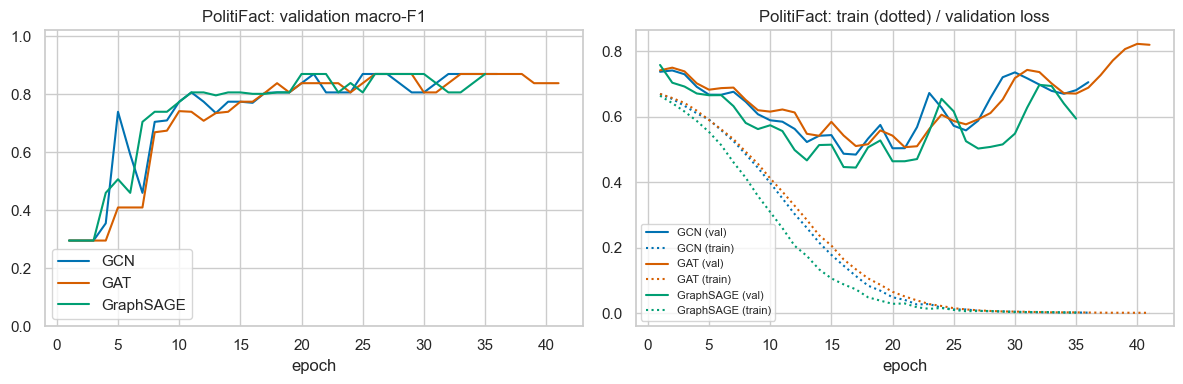

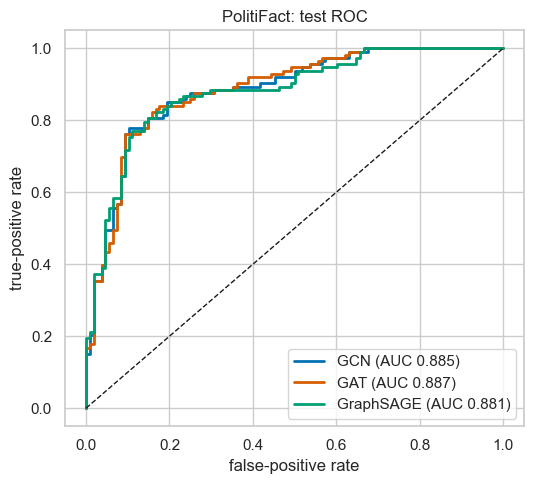

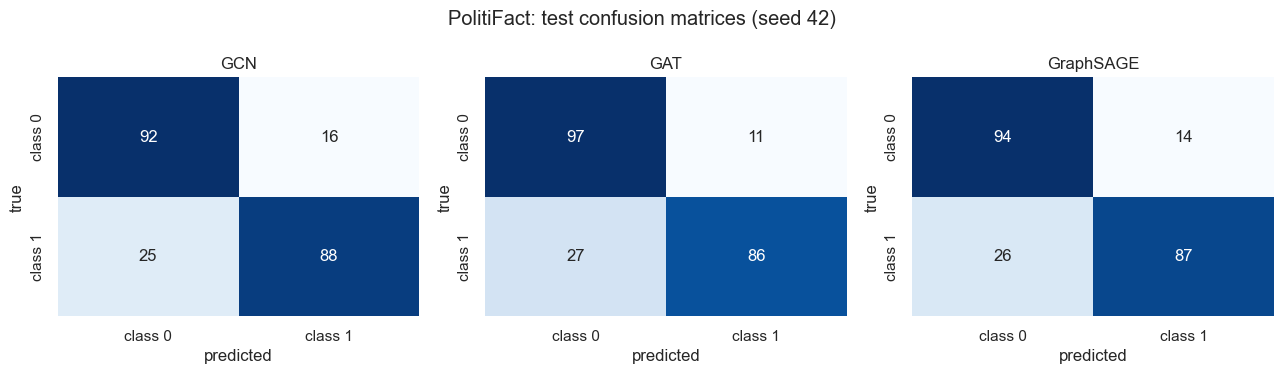

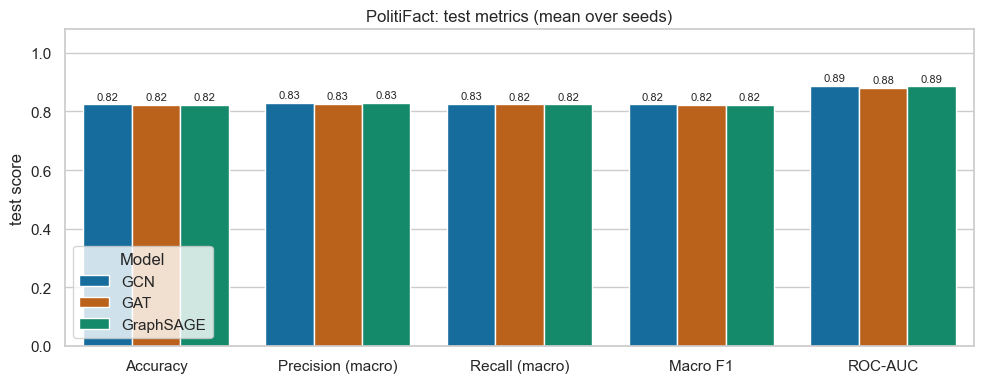

In [19]:
show_dataset_comparison("politifact")

### 7.2 GossipCop

,Dataset,Model,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,Accuracy std,Macro F1 std,Val macro-F1,Layers,Pooling,Root fusion,seeds,best epoch,epochs run,train time (s),parameters,peak GPU (MB),CPU memory (MB),train-val acc gap,val-train loss gap,test graphs
0,GossipCop,GCN,0.9491,0.9491,0.9491,0.9491,0.9854,0.0063,0.0063,0.9531,1,max,True,5,18.2,33.2,112.478,230018,NaN,1759.60,0.0234,0.0704,3826
1,GossipCop,GAT,0.9629,0.9630,0.9629,0.9629,0.9914,0.0054,0.0054,0.9600,1,max,True,5,24.0,39.0,118.870,230274,NaN,1772.32,0.0319,0.1002,3826
2,GossipCop,GraphSAGE,0.9664,0.9665,0.9664,0.9664,0.9935,0.0022,0.0022,0.9703,1,max,True,5,33.4,48.4,176.254,328322,NaN,1812.22,0.0289,0.1187,3826


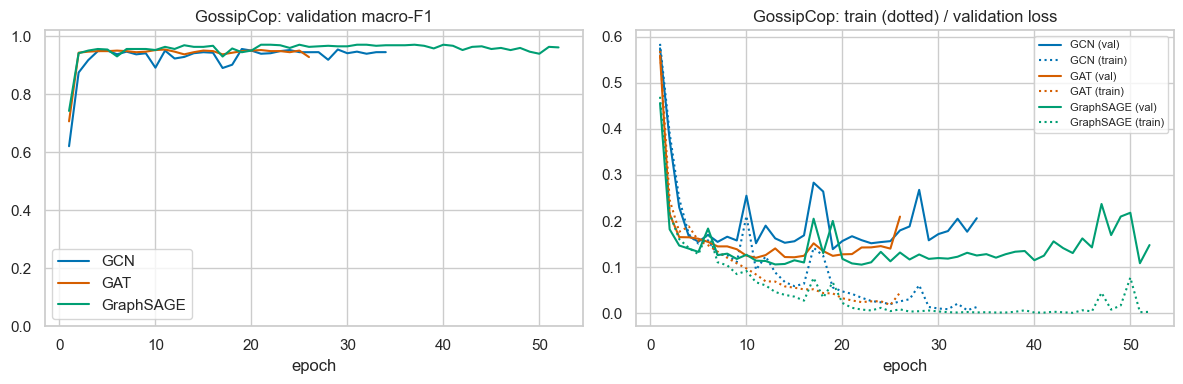

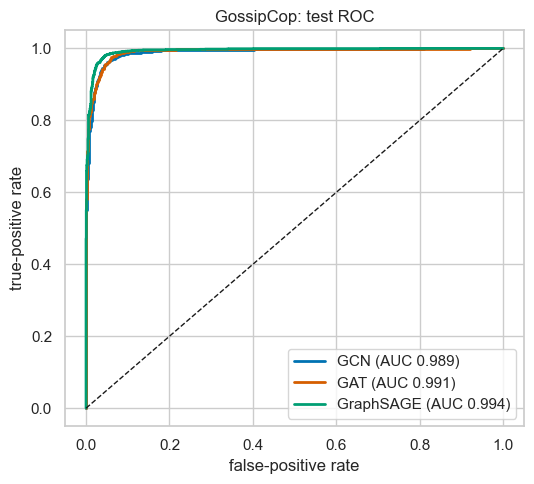

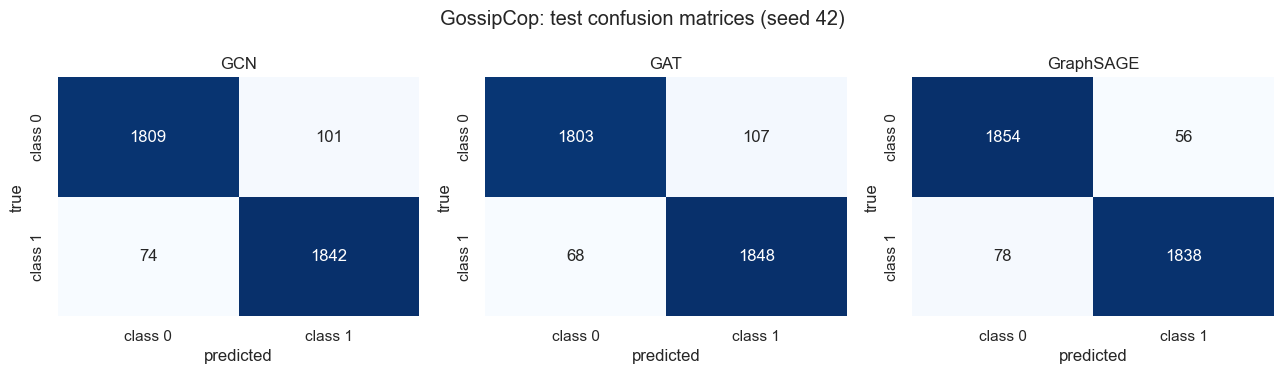

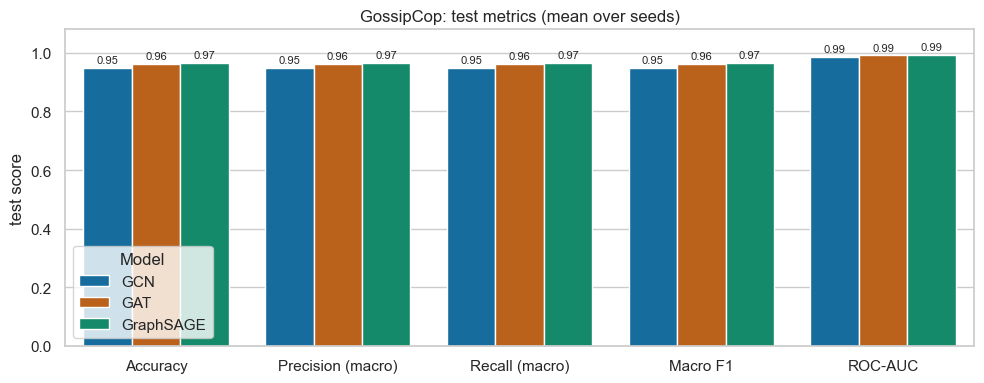

In [20]:
show_dataset_comparison("gossipcop")

## 8. Best model by validation and notes

In [21]:
# Find the best model by validation macro-F1. Notebook 04 reads the saved choice.
lines, best_val = [], {}
for ds in DATASETS:
    t = COMPARISON.get(ds)
    if t is None or t.empty:
        continue
    T = DATASET_TITLES[ds]
    top_test = t.sort_values("Macro F1", ascending=False).iloc[0]
    top_val = t.sort_values("Val macro-F1", ascending=False).iloc[0]
    best_val[ds] = top_val["Model"]
    lines.append(f"[{T}] best test macro-F1: {top_test['Model']} ({top_test['Macro F1']:.3f}); best validation macro-F1: {top_val['Model']} ({top_val['Val macro-F1']:.3f})")
    lines.append(f"[{T}] test macro-F1 mean ± std over {int(t['seeds'].min())} seeds: " + ", ".join(f"{r['Model']} {r['Macro F1']:.3f} ± {r['Macro F1 std']:.3f}" for _, r in t.iterrows()))
    lines.append(f"[{T}] test graphs: {int(t['test graphs'].iloc[0])} (one graph = {100 / t['test graphs'].iloc[0]:.2f} accuracy points)")
    lines.append(f"[{T}] training time (s): " + ", ".join(f"{r['Model']} {r['train time (s)']:.0f}" for _, r in t.iterrows()))
print("\n".join("- " + l for l in lines))

if best_val:
    save_json({"selection_rule": "highest mean validation macro-F1 (test set not used)", "setting": SETTING, "best_gnn_by_dataset": best_val},
              GNN_METRICS_DIR / "best_gnn_by_validation.json")
    save_json({"setting": SETTING, "edge_mode": EDGE_MODE, "readout": READOUT, "num_layers": NUM_LAYERS, "root_fusion": ROOT_FUSION,
               "cfg": CFG, "batch_size": BATCH_SIZE, "eval_batch_size": EVAL_BATCH_SIZE, "seeds": SEEDS}, GNN_METRICS_DIR / "gnn_config.json")

- [PolitiFact] best test macro-F1: GCN (0.824); best validation macro-F1: GraphSAGE (0.876)
- [PolitiFact] test macro-F1 mean ± std over 5 seeds: GCN 0.824 ± 0.007, GAT 0.822 ± 0.008, GraphSAGE 0.822 ± 0.008
- [PolitiFact] test graphs: 221 (one graph = 0.45 accuracy points)
- [PolitiFact] training time (s): GCN 14, GAT 14, GraphSAGE 15
- [GossipCop] best test macro-F1: GraphSAGE (0.966); best validation macro-F1: GraphSAGE (0.970)
- [GossipCop] test macro-F1 mean ± std over 5 seeds: GCN 0.949 ± 0.006, GAT 0.963 ± 0.005, GraphSAGE 0.966 ± 0.002
- [GossipCop] test graphs: 3826 (one graph = 0.03 accuracy points)
- [GossipCop] training time (s): GCN 112, GAT 119, GraphSAGE 176


Notes:
- A difference of a few points on the small PolitiFact test split is within noise; compare means and standard deviations over the five seeds.
- Edges are used as stored (parent to child), so the root receives no messages from users. Root fusion keeps its own vector available to the classifier. The official example makes edges undirected: set `EDGE_MODE = "undirected"` for that sensitivity run.
- The PolitiFact validation split has only 31 graphs, so the selection of GraphSAGE there (0.876 against 0.870) is weak evidence.
- Hyper-parameters are the same for every model and were not tuned per model.
- The fake/real label meaning is unverified, so classes are reported as class 0 / class 1.

## 9. Batch size and memory

These timings come from a single training epoch and one random seed. They are indicative measurements, not repeated hardware benchmarks.

In [22]:
# Time one training epoch of GraphSAGE at a given batch size.
def time_one_epoch(model_name, ds, batch_size):
    set_seed(SEEDS[0])
    model = MODEL_BUILDERS[model_name](EXPECTED_FEATURE_DIM).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    loader = DataLoader(GRAPHS[ds]["train"], batch_size=batch_size, shuffle=True)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    model.train()
    t0 = time.perf_counter()
    for batch in loader:
        batch = batch.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(batch.x, batch.edge_index, batch.batch, batch.ptr), batch.y)
        loss.backward()
        opt.step()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return {"dataset": DATASET_TITLES[ds], "model": model_name, "batch_size": batch_size, "epoch_seconds": round(time.perf_counter() - t0, 2),
            "peak_gpu_mb": round(torch.cuda.max_memory_allocated() / 1e6, 1) if DEVICE.type == "cuda" else None, "cpu_memory_mb": round(rss_mb(), 1)}


SCALE = pd.DataFrame([time_one_epoch("GraphSAGE", ds, bs) for ds in DATASETS for bs in (16, 32, 64, 128)])
save_dataframe(SCALE, GNN_METRICS_DIR / "batch_size_timing.csv")
display(SCALE)

,dataset,model,batch_size,epoch_seconds,peak_gpu_mb,cpu_memory_mb
0,PolitiFact,GraphSAGE,16,0.22,None,1816.7
1,PolitiFact,GraphSAGE,32,0.19,None,1838.2
2,PolitiFact,GraphSAGE,64,0.15,None,1829.2
3,PolitiFact,GraphSAGE,128,0.15,None,1829.3
4,GossipCop,GraphSAGE,16,2.37,None,1829.7
5,GossipCop,GraphSAGE,32,2.19,None,1846.6
6,GossipCop,GraphSAGE,64,1.93,None,1802.7
7,GossipCop,GraphSAGE,128,1.60,None,1826.9
